In [ ]:
import requests
import csv
import time
import xml.etree.ElementTree as ET
import os

BASE_URL = "https://dspace.mit.edu/oai/request"

ALL_CSV = "mit_oai_all.csv"
ORCID_CSV = "mit_oai_with_orcid.csv"
TOKEN_FILE = "resumption_token.txt"

HEADERS = [
    "oai_identifier",
    "title",
    "creators",
    "contributors",
    "subjects",
    "description",
    "publisher",
    "date",
    "type",
    "language",
    "relation",
    "source",
    "coverage",
    "rights",
    "identifiers",
    "formats",
    "orcid"
]

NAMESPACES = {
    "oai": "http://www.openarchives.org/OAI/2.0/",
    "oai_dc": "http://www.openarchives.org/OAI/2.0/oai_dc/",
    "dc": "http://purl.org/dc/elements/1.1/"
}


def extract_texts(parent, tag):
    return [el.text.strip() for el in parent.findall(tag, NAMESPACES) if el.text]


def find_orcid(values):
    for v in values:
        if "orcid.org" in v.lower():
            return v.strip()
    return ""


def save_token(token):
    with open(TOKEN_FILE, "w", encoding="utf-8") as f:
        f.write(token)


def load_token():
    if os.path.exists(TOKEN_FILE):
        with open(TOKEN_FILE, "r", encoding="utf-8") as f:
            return f.read().strip()
    return None


def harvest():
    token = load_token()

    if token:
        print("Продолжаем с токена:", token)
        params = {"verb": "ListRecords", "resumptionToken": token}
        mode = "a"
    else:
        print("Начинаем новый сбор")
        params = {"verb": "ListRecords", "metadataPrefix": "oai_dc"}
        mode = "w"

    total_records = 0
    request_count = 0

    with open(ALL_CSV, mode, newline="", encoding="utf-8") as all_f, \
         open(ORCID_CSV, mode, newline="", encoding="utf-8") as orcid_f:

        all_writer = csv.DictWriter(all_f, fieldnames=HEADERS)
        orcid_writer = csv.DictWriter(orcid_f, fieldnames=HEADERS)

        if mode == "w":
            all_writer.writeheader()
            orcid_writer.writeheader()

        while True:
            request_count += 1

            try:
                response = requests.get(BASE_URL, params=params, timeout=60)
                response.raise_for_status()
            except requests.exceptions.RequestException as e:
                print("Ошибка соединения:", e)
                print("Ждём 60 секунд и пробуем снова...")
                time.sleep(60)
                continue

            root = ET.fromstring(response.content)
            records = root.findall(".//oai:record", NAMESPACES)

            batch_count = 0

            for record in records:
                metadata = record.find("oai:metadata", NAMESPACES)
                if metadata is None:
                    continue

                dc = metadata.find("oai_dc:dc", NAMESPACES)
                if dc is None:
                    continue

                identifiers = extract_texts(dc, "dc:identifier")
                creators = extract_texts(dc, "dc:creator")
                contributors = extract_texts(dc, "dc:contributor")
                subjects = extract_texts(dc, "dc:subject")
                descriptions = extract_texts(dc, "dc:description")
                publishers = extract_texts(dc, "dc:publisher")
                dates = extract_texts(dc, "dc:date")
                types = extract_texts(dc, "dc:type")
                languages = extract_texts(dc, "dc:language")
                relations = extract_texts(dc, "dc:relation")
                sources = extract_texts(dc, "dc:source")
                coverages = extract_texts(dc, "dc:coverage")
                rights = extract_texts(dc, "dc:rights")
                formats = extract_texts(dc, "dc:format")

                orcid = find_orcid(
                    identifiers + creators + contributors + relations
                )

                row = {
                    "oai_identifier": record.findtext(
                        "oai:header/oai:identifier",
                        default="",
                        namespaces=NAMESPACES
                    ),
                    "title": "; ".join(extract_texts(dc, "dc:title")),
                    "creators": "; ".join(creators),
                    "contributors": "; ".join(contributors),
                    "subjects": "; ".join(subjects),
                    "description": " ".join(descriptions),
                    "publisher": "; ".join(publishers),
                    "date": "; ".join(dates),
                    "type": "; ".join(types),
                    "language": "; ".join(languages),
                    "relation": "; ".join(relations),
                    "source": "; ".join(sources),
                    "coverage": "; ".join(coverages),
                    "rights": "; ".join(rights),
                    "identifiers": "; ".join(identifiers),
                    "formats": "; ".join(formats),
                    "orcid": orcid
                }

                all_writer.writerow(row)
                if orcid:
                    orcid_writer.writerow(row)

                batch_count += 1
                total_records += 1

            all_f.flush()
            orcid_f.flush()

            print(
                f"Запрос #{request_count} | получено: {batch_count} | всего: {total_records}"
            )

            token_element = root.find(".//oai:resumptionToken", NAMESPACES)

            if token_element is None or not token_element.text:
                print("Сбор завершён полностью.")
                if os.path.exists(TOKEN_FILE):
                    os.remove(TOKEN_FILE)
                break

            token = token_element.text.strip()
            save_token(token)

            params = {"verb": "ListRecords", "resumptionToken": token}

            time.sleep(1)


if __name__ == "__main__":
    harvest()

Продолжаем с токена: oai_dc////64900
Запрос #1: получено 100 | всего добавлено: 100
Запрос #2: получено 100 | всего добавлено: 200
Запрос #3: получено 100 | всего добавлено: 300
Запрос #4: получено 100 | всего добавлено: 400
Запрос #5: получено 100 | всего добавлено: 500
Запрос #6: получено 100 | всего добавлено: 600
Запрос #7: получено 100 | всего добавлено: 700
Запрос #8: получено 100 | всего добавлено: 800
Запрос #9: получено 98 | всего добавлено: 898
Запрос #10: получено 100 | всего добавлено: 998
Запрос #11: получено 100 | всего добавлено: 1098
Запрос #12: получено 100 | всего добавлено: 1198
Запрос #13: получено 100 | всего добавлено: 1298
Запрос #14: получено 100 | всего добавлено: 1398
Запрос #15: получено 100 | всего добавлено: 1498
Запрос #16: получено 100 | всего добавлено: 1598
Запрос #17: получено 100 | всего добавлено: 1698
Запрос #18: получено 100 | всего добавлено: 1798
Запрос #19: получено 100 | всего добавлено: 1898
Запрос #20: получено 100 | всего добавлено: 1998
Зап

In [ ]:
import pandas as pd

ALL_FILE = "mit_oai_all.csv"
ORCID_FILE = "mit_oai_with_orcid.csv"

ALL_CLEAN = "mit_oai_all_clean.csv"
ORCID_CLEAN = "mit_oai_with_orcid_clean.csv"
ORCID_COUNTS = "orcid_counts.csv"

df_all = pd.read_csv(ALL_FILE)

before_all = len(df_all)
df_all = df_all.drop_duplicates(subset=["oai_identifier"])
after_all = len(df_all)

df_all.to_csv(ALL_CLEAN, index=False)

print(f"ALL: было {before_all}, стало {after_all}")

df_orcid = pd.read_csv(ORCID_FILE)

before_orcid = len(df_orcid)
df_orcid = df_orcid.drop_duplicates(subset=["oai_identifier"])
after_orcid = len(df_orcid)

df_orcid.to_csv(ORCID_CLEAN, index=False)

print(f"ORCID: было {before_orcid}, стало {after_orcid}")

orcid_counts = (
    df_orcid
    .groupby("orcid")
    .size()
    .reset_index(name="works_count")
    .sort_values("works_count", ascending=False)
)

orcid_counts.to_csv(ORCID_COUNTS, index=False)

print("Создан файл:", ORCID_COUNTS)
print("Всего уникальных ORCID:", len(orcid_counts))

ALL: было 151473, стало 151473
ORCID: было 27191, стало 27191
Создан файл: orcid_counts.csv
Всего уникальных ORCID: 5770


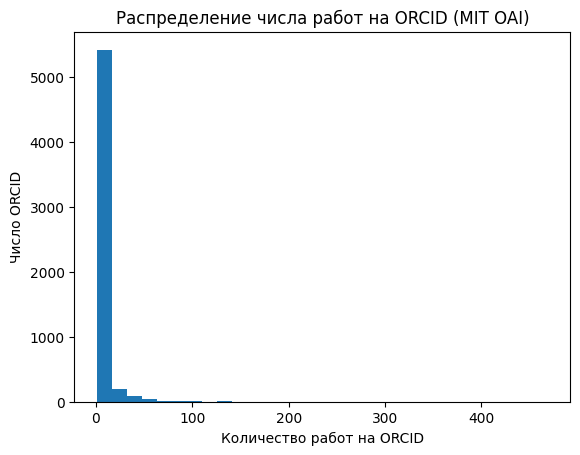

Всего ORCID: 5770
Среднее: 4.712478336221837
Медиана: 1.0
Максимум: 469


In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("orcid_counts.csv")

works = df["works_count"]

plt.figure()
plt.hist(works, bins=30)
plt.xlabel("Количество работ на ORCID")
plt.ylabel("Число ORCID")
plt.title("Распределение числа работ на ORCID (MIT OAI)")
plt.show()

print("Всего ORCID:", len(df))
print("Среднее:", works.mean())
print("Медиана:", works.median())
print("Максимум:", works.max())

In [12]:
works.quantile(0.0005)

np.float64(1.0)

Всего ORCID: 5770
ORCID с более чем одной работой: 2753


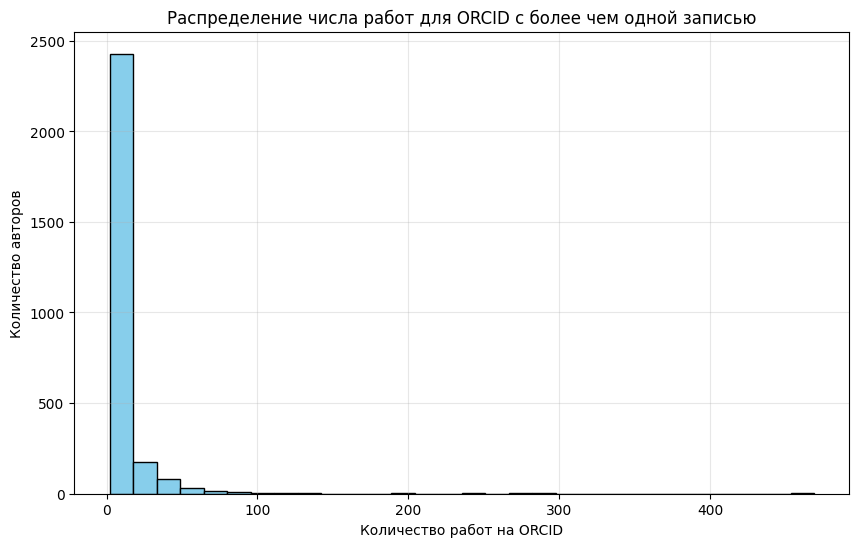

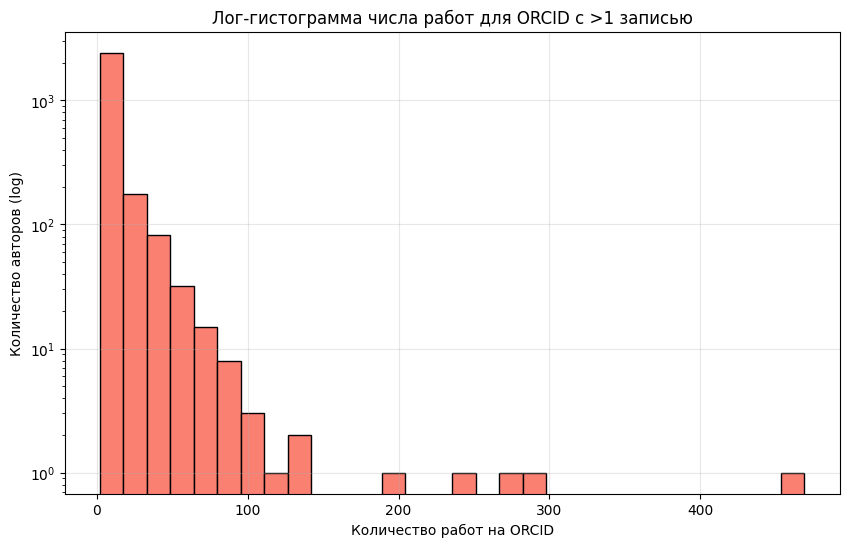

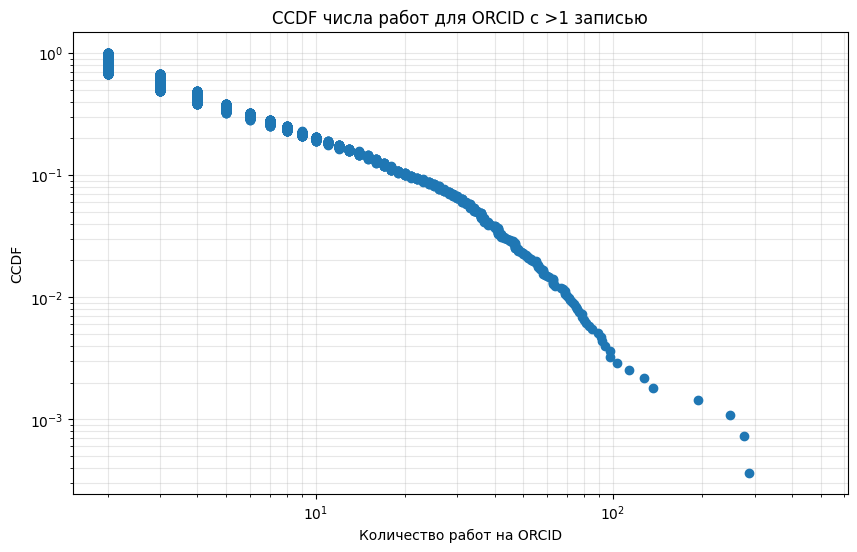

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Загружаем CSV
df = pd.read_csv("orcid_counts.csv")  # столбцы: orcid, works_count

# 1. Считаем, сколько ORCID имеют более одной работы
more_than_one = df[df['works_count'] > 1]
count_more_than_one = len(more_than_one)
total_orcid = len(df)

print(f"Всего ORCID: {total_orcid}")
print(f"ORCID с более чем одной работой: {count_more_than_one}")

# 2. Строим гистограмму распределения количества работ (для авторов с >1 работы)
plt.figure(figsize=(10,6))
plt.hist(more_than_one['works_count'], bins=30, color='skyblue', edgecolor='black')
plt.xlabel("Количество работ на ORCID")
plt.ylabel("Количество авторов")
plt.title("Распределение числа работ для ORCID с более чем одной записью")
plt.grid(True, alpha=0.3)
plt.show()

# 3. Логарифмическая гистограмма (для heavy-tail)
plt.figure(figsize=(10,6))
plt.hist(more_than_one['works_count'], bins=30, color='salmon', edgecolor='black', log=True)
plt.xlabel("Количество работ на ORCID")
plt.ylabel("Количество авторов (log)")
plt.title("Лог-гистограмма числа работ для ORCID с >1 записью")
plt.grid(True, alpha=0.3)
plt.show()

# 4. Опционально: CCDF (Complementary Cumulative Distribution Function)
import numpy as np

counts = np.sort(more_than_one['works_count'])
ccdf = 1.0 - np.arange(1, len(counts)+1)/len(counts)

plt.figure(figsize=(10,6))
plt.loglog(counts, ccdf, marker='o', linestyle='none')
plt.xlabel("Количество работ на ORCID")
plt.ylabel("CCDF")
plt.title("CCDF числа работ для ORCID с >1 записью")
plt.grid(True, which="both", alpha=0.3)
plt.show()

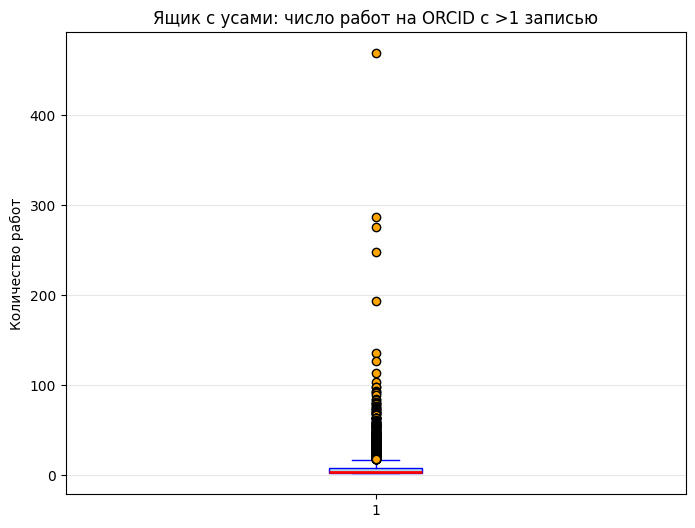

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Загружаем данные
df = pd.read_csv("orcid_counts.csv")

# Фильтруем авторов с более чем одной работой
more_than_one = df[df['works_count'] > 1]

# Строим ящик с усами
plt.figure(figsize=(8,6))
plt.boxplot(more_than_one['works_count'], vert=True, patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='blue'),
            whiskerprops=dict(color='blue'),
            capprops=dict(color='blue'),
            medianprops=dict(color='red', linewidth=2),
            flierprops=dict(marker='o', markerfacecolor='orange', markersize=6, linestyle='none'))
plt.ylabel("Количество работ")
plt.title("Ящик с усами: число работ на ORCID с >1 записью")
plt.grid(axis='y', alpha=0.3)
plt.show()

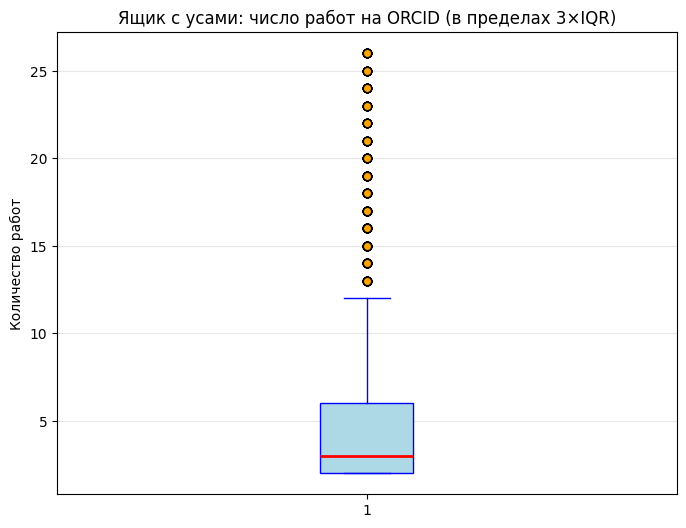

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Загружаем данные
df = pd.read_csv("orcid_counts.csv")

# Фильтруем авторов с более чем одной работой
more_than_one = df[df['works_count'] > 1]

# Рассчитываем 1-й и 3-й квартиль
Q1 = more_than_one['works_count'].quantile(0.25)
Q3 = more_than_one['works_count'].quantile(0.75)
IQR = Q3 - Q1

# Отбираем значения в пределах 3 * IQR
filtered = more_than_one[(more_than_one['works_count'] >= Q1 - 3*IQR) &
                         (more_than_one['works_count'] <= Q3 + 3*IQR)]

# Строим ящик с усами
plt.figure(figsize=(8,6))
plt.boxplot(filtered['works_count'], vert=True, patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='blue'),
            whiskerprops=dict(color='blue'),
            capprops=dict(color='blue'),
            medianprops=dict(color='red', linewidth=2),
            flierprops=dict(marker='o', markerfacecolor='orange', markersize=6, linestyle='none'))
plt.ylabel("Количество работ")
plt.title("Ящик с усами: число работ на ORCID (в пределах 3×IQR)")
plt.grid(axis='y', alpha=0.3)
plt.show()

In [5]:
filtered.describe()

,works_count
count,2542.000000
mean,5.221873
std,4.915455
min,2.000000
25%,2.000000
50%,3.000000
75%,6.000000
max,26.000000


In [7]:
filtered['works_count'].median()

np.float64(3.0)

In [ ]:
import pandas as pd

df = pd.read_csv("mit_oai_with_orcid.csv")

# уникальные типы документов
types = df["type"].value_counts()

print("Типы документов:")
print(types)

# записи, которые не являются статьями
non_articles = df[~df["type"].str.contains("Article", case=False, na=False)]

print("Количество не-статей:", len(non_articles))

print("Примеры не-статей:")
print(non_articles[["oai_identifier", "title", "type"]].head(10))

Типы документов:
type
Article; http://purl.org/eprint/type/JournalArticle                                                                                             21567
Article; http://purl.org/eprint/type/ConferencePaper                                                                                             3764
Thesis                                                                                                                                           1485
Article; http://purl.org/eprint/type/SubmittedJournalArticle                                                                                      202
Article; http://purl.org/eprint/type/BookItem                                                                                                      95
Article; http://purl.org/eprint/type/BookReview                                                                                                    36
Book chapter; http://purl.org/eprint/type/BookItem                            

In [9]:
df["abstract_length"] = df["description"].fillna("").str.len()

print("Средняя длина аннотации (символы):", df["abstract_length"].mean())
print("Медиана:", df["abstract_length"].median())

print("25 перцентиль:", df["abstract_length"].quantile(0.25))

Средняя длина аннотации (символы): 1308.9988231400096
Медиана: 1237.0
25 перцентиль: 933.0


In [13]:
df = pd.read_csv("mit_oai_with_orcid.csv")
df["subjects"].unique()

<StringArray>
[                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              nan,
                                                                                      

In [14]:
import pandas as pd
import re

INPUT_FILE = "mit_oai_all.csv"
OUTPUT_FILE = "russia_related_records.csv"

df = pd.read_csv(INPUT_FILE)

keywords = [

# страна
"russia",
"russian",
"russian federation",
"россия",
"российская федерация",
"рф",

# исторические
"soviet union",
"ussr",
"soviet",
"rsfsr",
"cccp",
"ссср",
"советский союз",

# регионы
"siberia",
"western siberia",
"eastern siberia",
"urals",
"ural mountains",
"volga region",
"yakutia",
"sakha republic",
"chechnya",
"dagestan",
"tatarstan",
"bashkortostan",
"karelia",
"kaliningrad",
"sakhalin",
"kamchatka",
"chukotka",

# города
"moscow",
"moskva",
"petersburg",
"novosibirsk",
"yekaterinburg",
"ekaterinburg",
"kazan",
"novgorod",
"samara",
"omsk",
"chelyabinsk",
"rostov on don",
"rostov-on-don",
"vladivostok",
"irkutsk",
"sochi",
"murmansk",
"arkhangelsk",
"khabarovsk",
"ulan ude",
"tyumen",
"perm",
"volgograd",

# география
"volga",
"don river",
"yenisei",
"ob river",
"lena river",
"lake baikal",
"baikal",
"caspian sea",

# политика
"kremlin",
"state duma",
"duma",
"federation council",

# лидеры
"vladimir putin",
"putin",
"dmitry medvedev",
"mikhail mishustin",
"sergei lavrov",
"sergei shoigu",
"valentina matviyenko",
"vyacheslav volodin",
"alexei navalny",
"yevgeny prigozhin",
"elvira nabiullina",

# компании
"gazprom",
"rosneft",
"sberbank",
"rosatom",
"norilsk nickel",
"lukoil",
"transneft",
"vtb bank",
"novatek",
"russian railways",
"aeroflot",
"roscosmos",
"rostec",

# научные организации
"moscow state university",
"higher school of economics",
"skolkovo",
"skoltech",
"bauman moscow state technical university",

# космос
"baikonur",
"soyuz spacecraft",
"progress spacecraft",
"mir space station",

# геополитика
"crimea",
"sevastopol",
"donbas",
"donetsk",
"luhansk",
"special military operation",
"russian armed forces",
]
# делаем pattern с границами слов
pattern = r"\b(" + "|".join(map(re.escape, keywords)) + r")\b"

search_columns = [
    "title",
    "description",
    "subjects",
    "coverage",
    "source"
]

df["search_text"] = df[search_columns].fillna("").agg(" ".join, axis=1)

mask = df["search_text"].str.contains(pattern, case=False, regex=True)

df_russia = df[mask]

df_russia.drop(columns=["search_text"], inplace=True)

df_russia.to_csv(OUTPUT_FILE, index=False)

print("Найдено записей:", len(df_russia))
print("Сохранено в:", OUTPUT_FILE)

C:\Users\Vizor\AppData\Local\Temp\ipykernel_27860\1117367275.py:153: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask = df["search_text"].str.contains(pattern, case=False, regex=True)


Найдено записей: 628
Сохранено в: russia_related_records.csv


In [2]:
import pandas as pd

FILE = "mit_oai_with_orcid_clean.csv"

df = pd.read_csv(FILE)

# проверяем наличие аннотации
df["has_abstract"] = df["description"].fillna("").str.strip() != ""

total = len(df)
with_abstract = df["has_abstract"].sum()
without_abstract = total - with_abstract

percent = with_abstract / total * 100

print("Всего записей:", total)
print("С аннотацией:", with_abstract)
print("Без аннотации:", without_abstract)
print(f"Процент с аннотацией: {percent:.2f}%")

Всего записей: 27191
С аннотацией: 27098
Без аннотации: 93
Процент с аннотацией: 99.66%


In [6]:
df["abstract_length"] = df["description"].fillna("").str.len()

print("Средняя длина аннотации (символы):", df["abstract_length"].mean())
print("Медиана:", df["abstract_length"].median())

print("25 перцентиль:", df["abstract_length"].quantile(0.25))

Средняя длина аннотации (символы): 1115.9074524066236
Медиана: 1029.0
25 перцентиль: 190.0


In [5]:
import pandas as pd

FILE = r"D:\MIT-collect\data\source_data\articles_without_orcid_filtered.csv"

df = pd.read_csv(FILE)

# проверяем наличие аннотации
df["has_abstract"] = df["description"].fillna("").str.strip() != ""

total = len(df)
with_abstract = df["has_abstract"].sum()
without_abstract = total - with_abstract

percent = with_abstract / total * 100

print("Всего записей:", total)
print("С аннотацией:", with_abstract)
print("Без аннотации:", without_abstract)
print(f"Процент с аннотацией: {percent:.2f}%")

Всего записей: 124282
С аннотацией: 114965
Без аннотации: 9317
Процент с аннотацией: 92.50%


In [3]:
import pandas as pd

FILE = "mit_oai_with_orcid_clean.csv"

df = pd.read_csv(FILE)

# определяем наличие аннотации
df["has_abstract"] = df["description"].fillna("").str.strip() != ""

# записи с аннотацией
with_abstract = df[df["has_abstract"]]

# записи без аннотации
without_abstract = df[~df["has_abstract"]]

print("=== Типы записей С аннотацией ===")
print(with_abstract["type"].value_counts())

print("\n=== Типы записей БЕЗ аннотации ===")
print(without_abstract["type"].value_counts())

=== Типы записей С аннотацией ===
type
Article; http://purl.org/eprint/type/JournalArticle                                                                                             21483
Article; http://purl.org/eprint/type/ConferencePaper                                                                                             3762
Thesis                                                                                                                                           1485
Article; http://purl.org/eprint/type/SubmittedJournalArticle                                                                                      199
Article; http://purl.org/eprint/type/BookItem                                                                                                      95
Article; http://purl.org/eprint/type/BookReview                                                                                                    36
Book chapter; http://purl.org/eprint/type/BookItem           